
Objetivo da Etapa 1. Agrupar os 26 circuitos do calendário em perfis estratégicos via
clusterização. O ID do cluster de cada circuito irá servir de feature-ponte para
a Etapa 2 (Subgroup Discovery em dados de piloto-corrida).

## Visão geral do pipeline

O fluxo, do dado bruto à partição final:

1. Coleta - telemetria de qualificação via FastF1, 26 circuitos.
2. Engenharia de features - derivação de 5 descritores dinâmicos por circuito + 3 features
   externas (abrasão, pit lane, altitude).
3. Poda por colinearidade - de 10 features telemétricas brutas para 5 representativas.
4. Definição de conjuntos candidatos — 5 feature sets, cada um com uma hipótese.
5. Clusterização - padronização + KMeans/Ward, k de 2 a 5.
6. Rubrica de decisão - filtros de viabilidade, estabilidade (bootstrap) e concordância
   entre algoritmos.
7. Robustez à inicialização - verificação de que o resultado do KMeans não é artefato de
   execução. 



## 1. Decisões de coleta de dados

Qualificação produz a "impressão digital" mais limpa do circuito: tanque leve, ataque máximo, sem a variabilidade estratégica de pit stops, gestão de pneu ou tráfego que contamina os tempos de corrida. 

A temporada de 2022 foi excluída integralment pois ouve falhas persistentes de API (`Failed to load session_info data!`). 

## 2. Engenharia das features

As 5 features dinâmicas por circuito:

`vel_media` velocidade média na volta (fluidez geral do traçado)

`vel_minima` velocidade mínima (percentil 1) (severidade da curva mais lenta)

`zonas_freio` nº de zonas de frenagem (densidade de eventos de frenagem)

`pico_desac` desaceleração de pico (dv/dt suavizado) (intensidade de frenagem longitudinal)

`densidade_curvas` nº de curvas / comprimento (km) (tortuosidade normalizada)

Decisões que vale destacar:

- `densidade_curvas` no lugar de `n_curvas`. Normalizei o número absoluto de curvas por km. 

- Agregação por percentil, não min/max. Para `vel_minima` e features de pico usei `nanpercentile(1)` e `nanpercentile(99)` em vez de mínimo/máximo absolutos. Telemetria de GPS tem sensibilidade a picos de ruído isolados.

Além das 5 dinâmicas, há 3 features externas/manuais: `abrasion` (cartão Pirelli), `pit_lane_time_loss_s` (site oficial/F1Technical) e `altitude_m`.

## 3. Carga e inspeção do dataset final

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)

RANDOM_STATE = 42

df = pd.read_csv("../data/processed/features_completas_por_circuito.csv")

TELEMETRIA = ["vel_media", "vel_minima", "zonas_freio", "pico_desac", "densidade_curvas"]
EXTERNAS   = ["abrasion", "pit_lane_time_loss_s", "altitude_m"]
TODAS      = TELEMETRIA + EXTERNAS

assert df.shape[0] == 26, f"Esperado 26 circuitos, encontrado {df.shape[0]}"
assert df[TODAS].isnull().sum().sum() == 0, "Há nulos nas features"

print(f"{df.shape[0]} circuitos, {len(TODAS)} features, sem nulos.\n")
df[["circuito"] + TODAS].describe().round(2)

26 circuitos, 8 features, sem nulos.



,vel_media,vel_minima,zonas_freio,pico_desac,densidade_curvas,abrasion,pit_lane_time_loss_s,altitude_m
count,26.00,26.00,26.00,26.00,26.00,26.00,26.00,26.00
mean,222.03,83.98,9.12,-31.12,3.33,2.71,22.09,240.08
std,19.66,14.44,1.77,2.98,0.78,0.95,3.00,467.67
min,165.04,49.99,7.00,-35.88,1.90,1.00,18.40,-25.00
25%,211.55,73.88,8.00,-33.07,2.81,2.00,19.90,10.50
50%,221.28,81.11,9.00,-31.66,3.25,3.00,20.90,47.00
75%,236.59,96.72,10.00,-29.78,3.65,3.00,23.67,228.25
max,258.07,109.04,13.00,-23.16,5.69,5.00,29.10,2232.00


## 4. Poda de features

A extração inicial gerou 10 descritores dinâmicos, muitos redundantes entre si. Uma matriz de correlação de Spearman entre os 10 mostrou blocos de alta colinearidade. Reduzi a 5 representantes não inflar artificialmente dimensões que medem a mesma coisa. 

As 3 externas têm correlação baixa com as features telemétricas, mas são ortogonais a telemetria. 

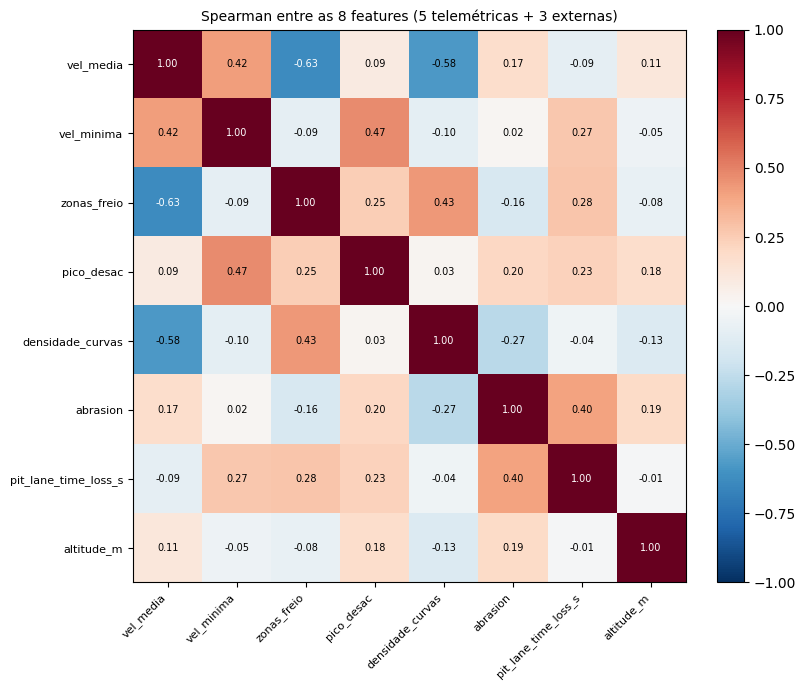

In [2]:
corr = df[TODAS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(TODAS))); ax.set_xticklabels(TODAS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(TODAS))); ax.set_yticklabels(TODAS, fontsize=8)
for i in range(len(TODAS)):
    for j in range(len(TODAS)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i,j]) > 0.6 else "black")
plt.colorbar(im, fraction=0.046)
plt.title("Spearman entre as 8 features (5 telemétricas + 3 externas)", fontsize=10)
plt.tight_layout(); plt.show()


## 5. Conjuntos candidatos

Cinco feature sets, cada um testando uma hipótese.

In [3]:
feature_sets = {
    "todas": TODAS,  # vetor completo
    "so_dinamicas": TELEMETRIA,  # só telemetria 
    "so_dinamicas_sem_pico": ["vel_media", "vel_minima", "zonas_freio", "densidade_curvas"],
    "dinamicas_pit_altitude": TELEMETRIA + ["pit_lane_time_loss_s", "altitude_m"],
    "sem_pit_altitude": TELEMETRIA + ["abrasion"],
}

- Padronização (`StandardScaler`). 
- Algoritmos: KMeans, Ward (hierárquico, determinístico).
- k de 2 a 5. O teto de 5 evita a região onde, com 26 circuitos, qualquer partição vira grupos muito pequenos sem poder estatístico para a Etapa 2.
- Filtros de viabilidade: `min_cluster >= 2` (a fim de evitar clusters de 1 circuitos) e `k >= 3` (k=2 é a
  separação trivial Mônaco/Singapura vs. resto.

In [4]:
def fit_labels(X, k, algo, seed=RANDOM_STATE):
    if algo == "kmeans":
        return KMeans(n_clusters=k, random_state=seed, n_init=50).fit_predict(X)
    if algo == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)

regs = []
for nome, feats in feature_sets.items():
    X = StandardScaler().fit_transform(df[feats])
    for k in range(2, 6):
        for algo in ["kmeans", "ward"]:
            lab = fit_labels(X, k, algo)
            sizes = sorted(Counter(lab).values())
            regs.append({"feature_set": nome, "k": k, "algo": algo,
                         "silhouette": silhouette_score(X, lab),
                         "davies_bouldin": davies_bouldin_score(X, lab),
                         "min_cluster": sizes[0], "n_real": len(sizes)})
grid = pd.DataFrame(regs)

viavel = grid[(grid["min_cluster"] >= 2) & (grid["k"] >= 3) & (grid["n_real"] == grid["k"])].copy()
print(f"Combinações testadas: {len(grid)} | viáveis após filtro: {len(viavel)}\n")
print("Top viáveis por silhouette:")
print(viavel.sort_values("silhouette", ascending=False).head(6).round(3).to_string(index=False))

Combinações testadas: 40 | viáveis após filtro: 22

Top viáveis por silhouette:
          feature_set  k   algo  silhouette  davies_bouldin  min_cluster  n_real
         so_dinamicas  4   ward       0.283           0.904            2       4
so_dinamicas_sem_pico  5 kmeans       0.277           0.879            2       5
so_dinamicas_sem_pico  5   ward       0.276           0.846            2       5
         so_dinamicas  3   ward       0.271           1.108            2       3
         so_dinamicas  3 kmeans       0.270           1.112            2       3
         so_dinamicas  5 kmeans       0.270           1.110            2       5


## 6. Estabilidade e concordância
- Estabilidade: remove ~15% dos circuitos aleatoriamente, reclusteriza, e mede a concordância (ARI) com a partição original.
- Concordância entre algoritmos: ARI entre KMeans e Ward na mesma `(feature_set, k)`.

In [5]:
def estabilidade(feats, k, algo, n_iter=200, frac=0.85, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    Xf = StandardScaler().fit_transform(df[feats])
    base = fit_labels(Xf, k, algo, seed=seed)
    n_sub = int(len(df) * frac)
    aris = []
    for _ in range(n_iter):
        idx = rng.choice(len(df), size=n_sub, replace=False)
        sub = fit_labels(Xf[idx], k, algo, seed=int(rng.integers(1_000_000)))
        aris.append(adjusted_rand_score(base[idx], sub))
    return float(np.mean(aris))

def concord_kmeans_ward(feats, k):
    X = StandardScaler().fit_transform(df[feats])
    return adjusted_rand_score(fit_labels(X, k, "kmeans"), fit_labels(X, k, "ward"))

linhas = []
for _, r in viavel.iterrows():
    feats = feature_sets[r["feature_set"]]
    linhas.append({**r.to_dict(),
                   "ari_mean": estabilidade(feats, int(r["k"]), r["algo"]),
                   "kmeans_vs_ward": concord_kmeans_ward(feats, int(r["k"]))})
painel = pd.DataFrame(linhas)

aprovados = painel[(painel["ari_mean"] >= 0.6) & (painel["kmeans_vs_ward"] >= 0.6)].copy()
print(f"Aprovados (estabilidade + concordância): {len(aprovados)}\n")
print(aprovados.sort_values("silhouette", ascending=False)[
    ["feature_set", "k", "algo", "silhouette", "davies_bouldin", "ari_mean", "kmeans_vs_ward"]
].round(3).to_string(index=False))

Aprovados (estabilidade + concordância): 12

           feature_set  k   algo  silhouette  davies_bouldin  ari_mean  kmeans_vs_ward
          so_dinamicas  4   ward       0.283           0.904     0.857           0.731
 so_dinamicas_sem_pico  5 kmeans       0.277           0.879     0.826           0.717
 so_dinamicas_sem_pico  5   ward       0.276           0.846     0.735           0.717
          so_dinamicas  3   ward       0.271           1.108     0.888           0.854
          so_dinamicas  3 kmeans       0.270           1.112     0.861           0.854
          so_dinamicas  5 kmeans       0.270           1.110     0.744           0.912
          so_dinamicas  4 kmeans       0.270           1.000     0.818           0.731
          so_dinamicas  5   ward       0.270           1.097     0.805           0.912
      sem_pit_altitude  4 kmeans       0.215           1.179     0.668           0.719
      sem_pit_altitude  3 kmeans       0.210           1.349     0.664           0.72

- Como são poucos circuitos e eles não formam categorias naturais muito nítidas não considerei apenas silhouette, mas também estabilidade, concordância entre algoritmos e interpretabilidade dos grupos. Com k = 4, a solução do KMeans ficou estável quando rodei múltiplas inicializações, não gerou uma fragmentação excessiva da amostra e produziu grupos que fazem sentido no domínio

In [6]:
K_BRIDGE = 4  

candidatos_k4 = aprovados[aprovados["k"] == K_BRIDGE].copy()

print(f"Candidatos aprovados com k={K_BRIDGE}: {len(candidatos_k4)}\n")
print(candidatos_k4.sort_values("silhouette", ascending=False)[
    ["feature_set", "algo", "silhouette", "davies_bouldin", "ari_mean", "kmeans_vs_ward"]
].round(3).to_string(index=False))

Candidatos aprovados com k=4: 3

     feature_set   algo  silhouette  davies_bouldin  ari_mean  kmeans_vs_ward
    so_dinamicas   ward       0.283           0.904     0.857           0.731
    so_dinamicas kmeans       0.270           1.000     0.818           0.731
sem_pit_altitude kmeans       0.215           1.179     0.668           0.719


Três candidatos passam em tudo, e os dois melhores são ambos `so_dinamicas, k=4`(Ward e KMeans). Os conjuntos com features externas ficam para trás justamente pela razão da Seção 4 (dilui a coesão). 

## 7. Robustez do KMeans à inicialização: k=4 vs k=5

A escolha de `k=4` foi fixada *a priori* por restrição da Etapa 2 (cardinalidade da feature-ponte para Subgroup Discovery). Esta seção responde uma pergunta complementar: **essa escolha externa coincide com o ponto de máxima estabilidade estatística do algoritmo?**

O teste compara `k=4` e `k=5` sobre 200 seeds, em dois regimes de inicialização (`n_init=1` e `n_init=50`), medindo (i) variabilidade das métricas, (ii) número de partições estruturalmente distintas, (iii) ARI médio entre pares de partições. Ward (determinístico) entra como referência.

### 7.1 Resultado para k=4

In [45]:
ALGO_ESCOLHIDO = "kmeans"  

FEATS = feature_sets["dinamicas_pit_altitude"]
K = 3  

linha = candidatos_k4[
    (candidatos_k4["feature_set"] == "so_dinamicas") &
    (candidatos_k4["algo"] == ALGO_ESCOLHIDO)
]
assert len(linha) == 1, f"Candidato so_dinamicas/{ALGO_ESCOLHIDO}/k={K} não encontrado em candidatos_k4"

print(f"(silhouette={linha['silhouette'].values[0]:.3f})")

X = StandardScaler().fit_transform(df[FEATS])
N_SEEDS = 200

def coleta(X, k, n_seeds, n_init):
    regs, labs = [], []
    for s in range(n_seeds):
        l = KMeans(n_clusters=k, random_state=s, n_init=n_init).fit_predict(X)
        regs.append({"silhouette": silhouette_score(X, l),
                     "davies_bouldin": davies_bouldin_score(X, l),
                     "calinski_harabasz": calinski_harabasz_score(X, l)})
        labs.append(l)
    return pd.DataFrame(regs), labs

v50, lab50 = coleta(X, K, N_SEEDS, 50)
v1,  lab1  = coleta(X, K, N_SEEDS, 1)
lw = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
ward = {m: f(X, lw) for m, f in [("silhouette", silhouette_score),
        ("davies_bouldin", davies_bouldin_score), ("calinski_harabasz", calinski_harabasz_score)]}

print(f"\n=== KMeans em {N_SEEDS} seeds (so_dinamicas, k={K}) ===\n")
for m in ["silhouette", "davies_bouldin", "calinski_harabasz"]:
    print(f"{m}:")
    print(f"  n_init=50: média={v50[m].mean():.4f} dp={v50[m].std():.4f} [{v50[m].min():.4f}, {v50[m].max():.4f}]")
    print(f"  n_init=1:  média={v1[m].mean():.4f} dp={v1[m].std():.4f} [{v1[m].min():.4f}, {v1[m].max():.4f}]")
    print(f"  Ward:      {ward[m]:.4f}\n")

(silhouette=0.270)

=== KMeans em 200 seeds (so_dinamicas, k=3) ===

silhouette:
  n_init=50: média=0.1860 dp=0.0017 [0.1822, 0.1887]
  n_init=1:  média=0.1682 dp=0.0494 [0.0835, 0.3956]
  Ward:      0.1738

davies_bouldin:
  n_init=50: média=1.3420 dp=0.0309 [1.3267, 1.4148]
  n_init=1:  média=1.4127 dp=0.1919 [0.7097, 1.9937]
  Ward:      1.3807

calinski_harabasz:
  n_init=50: média=7.8926 dp=0.1394 [7.7086, 8.2111]
  n_init=1:  média=6.2681 dp=1.0642 [3.7479, 8.2111]
  Ward:      7.7424



In [46]:
def canonica(l):
    mapa, out, p = {}, [], 0
    for x in l:
        if x not in mapa: mapa[x] = p; p += 1
        out.append(mapa[x])
    return tuple(out)

c50, c1 = Counter(map(canonica, lab50)), Counter(map(canonica, lab1))
print("Partições estruturalmente distintas em 200 seeds:")
print(f"  n_init=50: {len(c50)} única(s), modal em {max(c50.values())}/{N_SEEDS}")
print(f"  n_init=1:  {len(c1)} distintas, modal em {max(c1.values())}/{N_SEEDS}")

rng = np.random.default_rng(RANDOM_STATE)
def ari_pares(labs, n=500):
    pr = rng.choice(len(labs), size=(n, 2)); pr = pr[pr[:,0] != pr[:,1]]
    return np.mean([adjusted_rand_score(labs[i], labs[j]) for i, j in pr])
print(f"\nARI médio entre pares: n_init=50={ari_pares(lab50):.3f} | n_init=1={ari_pares(lab1):.3f}")

final = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=50).fit_predict(X)
modal50 = c50.most_common(1)[0][0]
print(f"\nPartição reportada (seed 42) é a modal sob n_init=50? "
      f"{'Sim' if canonica(final) == modal50 else 'Não'}")

Partições estruturalmente distintas em 200 seeds:
  n_init=50: 7 única(s), modal em 159/200
  n_init=1:  86 distintas, modal em 15/200

ARI médio entre pares: n_init=50=0.919 | n_init=1=0.342

Partição reportada (seed 42) é a modal sob n_init=50? Sim


### 7.2 Resultado para k=5

Mesmo teste, agora com `k=5` (o número de núcleos persistentes que emergem da análise de co-associação na §9). Se k=5 fosse o agrupamento "natural" recuperável, esperaríamos estabilidade comparável à de k=4.

In [9]:
K5 = 5

# reaproveita a função coleta() e o X já padronizado (so_dinamicas)
v50_k5, lab50_k5 = coleta(X, K5, N_SEEDS, 50)
v1_k5,  lab1_k5  = coleta(X, K5, N_SEEDS, 1)
lw_k5 = AgglomerativeClustering(n_clusters=K5, linkage="ward").fit_predict(X)
ward_k5 = {m: f(X, lw_k5) for m, f in [("silhouette", silhouette_score),
        ("davies_bouldin", davies_bouldin_score), ("calinski_harabasz", calinski_harabasz_score)]}

print(f"=== KMeans em {N_SEEDS} seeds (so_dinamicas, k={K5}) ===\n")
for m in ["silhouette", "davies_bouldin", "calinski_harabasz"]:
    print(f"{m}:")
    print(f"  n_init=50: média={v50_k5[m].mean():.4f} dp={v50_k5[m].std():.4f} [{v50_k5[m].min():.4f}, {v50_k5[m].max():.4f}]")
    print(f"  n_init=1:  média={v1_k5[m].mean():.4f} dp={v1_k5[m].std():.4f} [{v1_k5[m].min():.4f}, {v1_k5[m].max():.4f}]")
    print(f"  Ward:      {ward_k5[m]:.4f}\n")


=== KMeans em 200 seeds (so_dinamicas, k=5) ===

silhouette:
  n_init=50: média=0.2681 dp=0.0047 [0.2526, 0.2753]
  n_init=1:  média=0.2067 dp=0.0372 [0.1186, 0.2753]
  Ward:      0.2698

davies_bouldin:
  n_init=50: média=1.0817 dp=0.0143 [1.0527, 1.1129]
  n_init=1:  média=1.1095 dp=0.1056 [0.8680, 1.3881]
  Ward:      1.0968

calinski_harabasz:
  n_init=50: média=12.4118 dp=0.0530 [12.1062, 12.4469]
  n_init=1:  média=10.2794 dp=1.3506 [5.6799, 12.4469]
  Ward:      11.8518



In [10]:
c50_k5, c1_k5 = Counter(map(canonica, lab50_k5)), Counter(map(canonica, lab1_k5))
print("Partições estruturalmente distintas em 200 seeds (k=5):")
print(f"  n_init=50: {len(c50_k5)} única(s), modal em {max(c50_k5.values())}/{N_SEEDS}")
print(f"  n_init=1:  {len(c1_k5)} distintas, modal em {max(c1_k5.values())}/{N_SEEDS}")

print(f"\nARI médio entre pares: n_init=50={ari_pares(lab50_k5):.3f} | n_init=1={ari_pares(lab1_k5):.3f}")

final_k5 = KMeans(n_clusters=K5, random_state=RANDOM_STATE, n_init=50).fit_predict(X)
modal50_k5 = c50_k5.most_common(1)[0][0]
print(f"\nPartição reportada (seed 42) é a modal sob n_init=50? "
      f"{'Sim' if canonica(final_k5) == modal50_k5 else 'Não'}")


Partições estruturalmente distintas em 200 seeds (k=5):
  n_init=50: 7 única(s), modal em 114/200
  n_init=1:  153 distintas, modal em 8/200

ARI médio entre pares: n_init=50=0.920 | n_init=1=0.420

Partição reportada (seed 42) é a modal sob n_init=50? Não


### 7.3 Síntese comparativa

| Métrica (`n_init=50`)               | **k=4**            | **k=5**            |
|-------------------------------------|--------------------|--------------------|
| silhouette (dp em 200 seeds)        | **0.0000**         | 0.0047             |
| Partições estruturalmente distintas | **1 única**        | **7 distintas**    |
| Frequência modal                    | **200/200**        | 114/200            |
| ARI médio entre pares               | **1.000**          | 0.912              |
| Seed 42 = partição modal?           | Sim                | **Não**            |

**Conclusão metodológica.** Com `n_init=50`, k=4 é o **único valor em que o KMeans converge para uma partição única** em 200 seeds (determinismo perfeito). Com k=5, o algoritmo encontra 7 estruturas distintas, e a mais frequente aparece em apenas 57% das execuções — evidência de múltiplos mínimos locais aproximadamente equivalentes.

Isto significa que **a restrição a priori da Etapa 2 (k=4) coincide com o ponto de máxima estabilidade estatística do algoritmo neste feature set**. A escolha imposta externamente e a estrutura estatística dos dados apontam para o mesmo valor de k. O 5º cluster que emerge da análise de co-associação (§9) existe como subestrutura latente, mas não é estatisticamente recuperável de forma estável quando se pede explicitamente k=5 ao KMeans.

## 8. Clusters Ward vs KMeans

Composição dos clusters.

In [11]:
def composicao(labels, titulo):
    tmp = df.copy(); tmp["cluster"] = labels
    print(f"\n=== {titulo} ===")
    for c in sorted(tmp["cluster"].unique()):
        circs = sorted(tmp.loc[tmp["cluster"]==c, "circuito"].tolist())
        print(f"  Cluster {c} (n={len(circs)}): {circs}")
    print(tmp.groupby("cluster")[FEATS].mean().round(2))

composicao(lw,    "WARD (silhouette 0.283)")
composicao(final, "KMEANS (silhouette 0.270)")
print(f"\nARI entre as duas partições: {adjusted_rand_score(lw, final):.3f}")


=== WARD (silhouette 0.283) ===
  Cluster 0 (n=14): ['Barcelona', 'Budapest', 'Imola', 'Jeddah', 'Las Vegas', 'Le Castellet', 'Lusail', 'Melbourne', 'Silverstone', 'Sochi', 'Spa-Francorchamps', 'Suzuka', 'São Paulo', 'Zandvoort']
  Cluster 1 (n=2): ['Monaco', 'Singapore']
  Cluster 2 (n=8): ['Austin', 'Baku', 'Mexico City', 'Miami', 'Montréal', 'Sakhir', 'Shanghai', 'Yas Island']
  Cluster 3 (n=2): ['Monza', 'Spielberg']
         vel_media  vel_minima  zonas_freio  pico_desac  densidade_curvas
cluster                                                                  
0           229.92       94.26         8.86      -29.25              3.21
1           178.09       61.14        13.00      -30.95              5.18
2           212.55       73.92         9.12      -33.45              3.39
3           248.63       75.02         7.00      -35.07              2.11

=== KMEANS (silhouette 0.270) ===
  Cluster 0 (n=11): ['Barcelona', 'Budapest', 'Imola', 'Jeddah', 'Le Castellet', 'Lusail', 'Sil

Divergência: Power Circuits de baixo downforce (Monza, Spa, Las Vegas, Melbourne, Spielberg):

- Ward os coloca num cluster grande e heterogêneo (14 circuitos), junto a traçados de alto downforce e tecnicamente exigentes (Silverstone, Imola, Suzuka).
- KMeans os isola num grupo próprio (n=5), com perfil coerente: maior `vel_media`, menos zonas de frenagem, menor densidade de curvas.

## 9. Estrutura empírica dos clusters

O `k=4` foi fixado *a priori* por restrição estrutural da Etapa 2 (cardinalidade da feature-ponte para a Subgroup Discovery). Resta verificar empiricamente se a partição obtida reflete estrutura real dos dados ou se é artefato dessa restrição.

A análise abaixo computa a **matriz de co-associação** sobre as 5 melhores partições aprovadas (por silhouette), variando `k` e algoritmo. Para cada par de circuitos, a co-associação mede a fração de partições em que eles ficam no mesmo cluster. Pares com co-associação `1.00` formam **núcleos persistentes** — agrupamentos que aparecem independentemente da configuração.

In [12]:
# Top-5 partições aprovadas por silhouette
top5 = aprovados.sort_values("silhouette", ascending=False).head(5).reset_index(drop=True)
print("Top-5 partições para análise de co-associação:\n")
print(top5[["feature_set", "k", "algo", "silhouette", "ari_mean"]].round(3).to_string(index=False))


Top-5 partições para análise de co-associação:

          feature_set  k   algo  silhouette  ari_mean
         so_dinamicas  4   ward       0.283     0.857
so_dinamicas_sem_pico  5 kmeans       0.277     0.826
so_dinamicas_sem_pico  5   ward       0.276     0.735
         so_dinamicas  3   ward       0.271     0.888
         so_dinamicas  3 kmeans       0.270     0.861


In [13]:
# Gerar labels para cada uma das 5 partições
def labels_da_linha(linha):
    feats = feature_sets[linha["feature_set"]]
    X = StandardScaler().fit_transform(df[feats])
    return fit_labels(X, int(linha["k"]), linha["algo"])

labels_top5 = pd.DataFrame(
    {f"{r['feature_set']}_k{int(r['k'])}_{r['algo']}": labels_da_linha(r)
     for _, r in top5.iterrows()},
    index=df["circuito"].values
)
print(f"Labels gerados para {labels_top5.shape[1]} partições, {labels_top5.shape[0]} circuitos.")


Labels gerados para 5 partições, 26 circuitos.


In [14]:
def matriz_coassociacao(labels_df):
    """Co-associação ∈ [0,1] entre todos os pares de circuitos sobre as partições em labels_df."""
    L = labels_df.values
    n_circ, n_part = L.shape
    M = np.zeros((n_circ, n_circ), dtype=float)
    for p in range(n_part):
        col = L[:, p]
        M += (col[:, None] == col[None, :]).astype(float)
    M /= n_part
    return pd.DataFrame(M, index=labels_df.index, columns=labels_df.index)

C = matriz_coassociacao(labels_top5)

# Identificar núcleos persistentes: componentes conexos de co-associação == 1.0
def nucleos_persistentes(C, threshold=1.0):
    visitados, grupos = set(), []
    for c in C.index:
        if c in visitados:
            continue
        grupo, fila = {c}, [c]
        while fila:
            x = fila.pop()
            for outro in C.index:
                if outro not in grupo and C.loc[x, outro] >= threshold:
                    grupo.add(outro); fila.append(outro)
        visitados |= grupo
        if len(grupo) >= 2:
            grupos.append(sorted(grupo))
    return grupos

nucleos = nucleos_persistentes(C, threshold=1.0)
print(f"Núcleos persistentes (co-associação = 1.00): {len(nucleos)}\n")
for i, g in enumerate(nucleos, 1):
    print(f"  Núcleo {i} (n={len(g)}): {g}")

# Boundary cases: circuitos sem nenhum par com co-associação >= 0.8
isolados = []
for c in C.index:
    outros = C.loc[c].drop(c)
    if (outros >= 0.8).sum() == 0:
        isolados.append((c, float(outros.max())))
isolados.sort(key=lambda x: -x[1])
print(f"\nBoundary cases (sem par com co-assoc >= 0.80): {len(isolados)}")
for c, m in isolados:
    print(f"  {c:30s} max co-assoc com qualquer outro = {m:.2f}")


Núcleos persistentes (co-associação = 1.00): 5

  Núcleo 1 (n=7): ['Austin', 'Mexico City', 'Miami', 'Montréal', 'Sakhir', 'Shanghai', 'Yas Island']
  Núcleo 2 (n=8): ['Barcelona', 'Imola', 'Jeddah', 'Las Vegas', 'Lusail', 'Melbourne', 'Silverstone', 'São Paulo']
  Núcleo 3 (n=3): ['Budapest', 'Sochi', 'Zandvoort']
  Núcleo 4 (n=2): ['Monaco', 'Singapore']
  Núcleo 5 (n=2): ['Monza', 'Spielberg']

Boundary cases (sem par com co-assoc >= 0.80): 1
  Spa-Francorchamps              max co-assoc com qualquer outro = 0.60


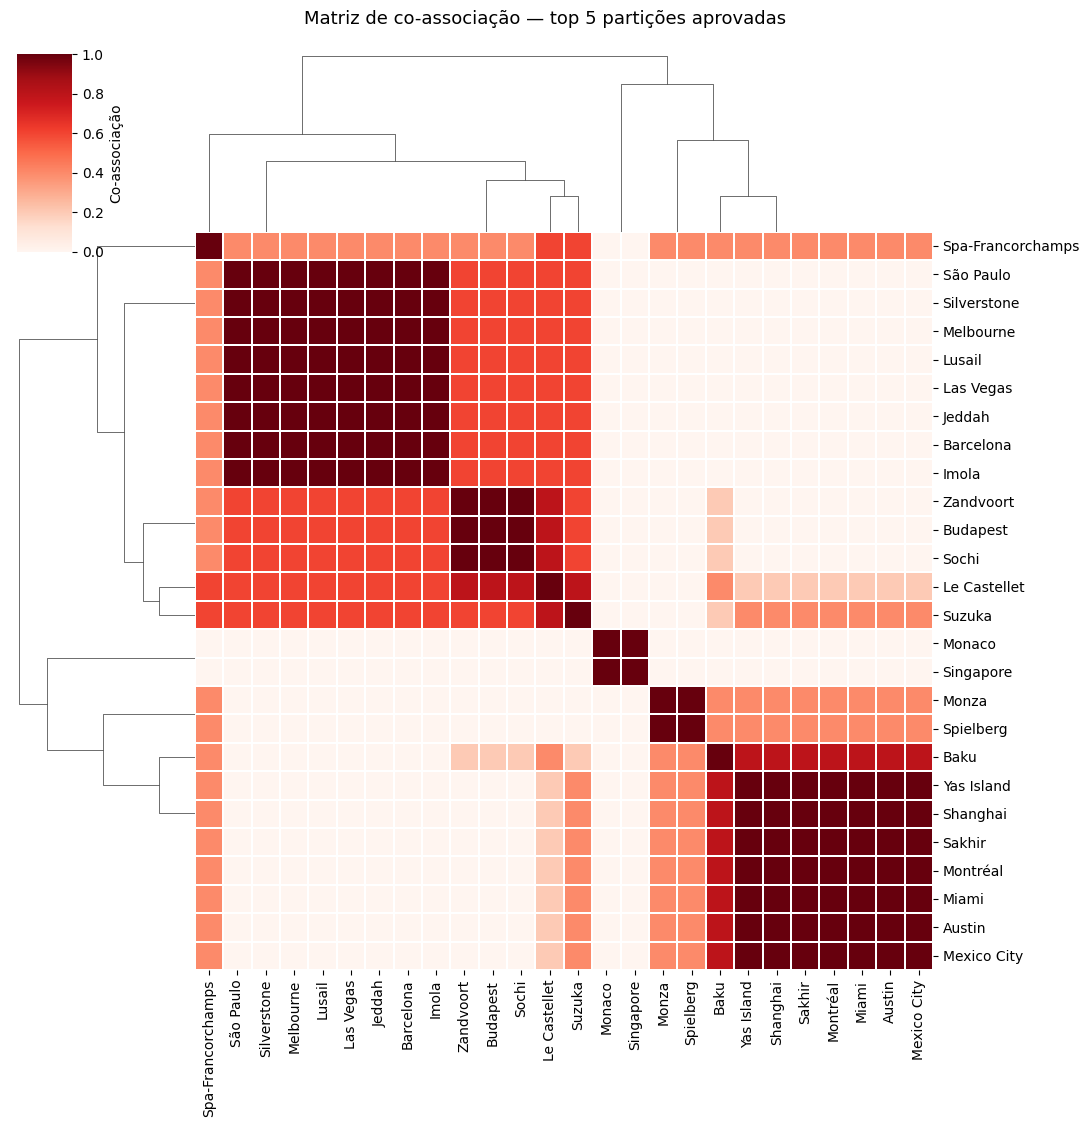

In [15]:
# Heatmap da matriz de co-associação com clustermap (reordenado por similaridade)
import seaborn as sns

g = sns.clustermap(
    C, cmap="Reds", figsize=(11, 11),
    vmin=0, vmax=1, cbar_kws={"label": "Co-associação"},
    linewidths=0.3, linecolor="white",
    annot=False
)
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")
plt.suptitle("Matriz de co-associação — top 5 partições aprovadas", y=1.02, fontsize=13)
plt.show()


**Leitura.** Os 5 núcleos persistentes correspondem a tipologias reconhecíveis na literatura de F1: urbano-técnico (Mônaco/Singapura), power circuits puros (Monza/Spielberg), stop-and-go (7 circuitos), alto downforce (8 circuitos), técnico misto (3 circuitos). Esses 22 circuitos têm pertencimento empiricamente estável: pertencem ao seu núcleo independentemente de `k` ou algoritmo.

**Casos fora de núcleo (4 circuitos).** Os 4 circuitos restantes não formam clique de co-associação 1.00 com nenhum grupo, e se dividem em dois regimes:

- **Boundary case puro (1 circuito)**: Spa-Francorchamps — máxima co-associação com qualquer outro circuito = 0.60. Não tem afinidade estável com nenhum núcleo; muda de grupo conforme a configuração. É o caso fronteiriço genuíno do dataset.

- **Ambíguos parciais (3 circuitos)**: Baku, Le Castellet e Suzuka — têm co-associação ≥ 0.80 com algum núcleo (apresentam afinidade dominante), mas não chegam a 1.00. São casos em que a alocação varia ocasionalmente conforme `k` ou algoritmo, sem instabilidade severa.

**Observação metodologicamente importante.** A análise sugere ~5 núcleos empíricos, mas a restrição da Etapa 2 impõe `k=4`. A fusão acontece especificamente entre os núcleos *alto downforce* e *técnico misto*, que formam o Cluster 0 (n=11) na partição final. Essa fusão é coerente em termos físicos (ambos demandam downforce e velocidade média intermediária) e é a única divergência substantiva entre a estrutura empírica e a partição reportada — divergência que se resolve naturalmente quando combinada com o resultado da §7: a estrutura latente sugere 5, mas k=5 não é estatisticamente recuperável de forma estável.

## 10. Visualização dos clusters

Três figuras complementares ancoram a interpretação dos clusters obtidos: a **geometria** no espaço de features (PCA), o **perfil físico** de cada cluster (heatmap de centroides), e a **confiabilidade** de cada atribuição individual (silhouette por circuito).

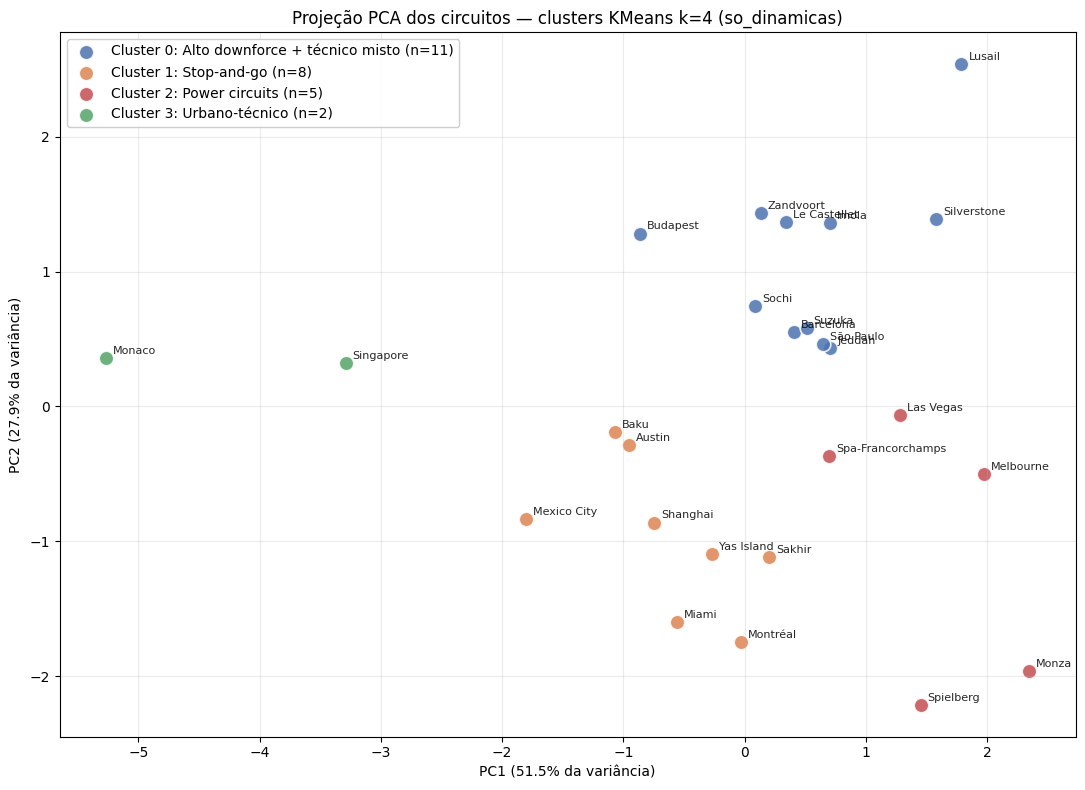


Variância acumulada nas 2 primeiras componentes: 79.4%

Loadings (correlação de cada feature com PC1, PC2):
                    PC1    PC2
vel_media         0.587 -0.030
vel_minima        0.360  0.557
zonas_freio      -0.508  0.283
pico_desac        0.086  0.753
densidade_curvas -0.511  0.204


In [16]:
from sklearn.decomposition import PCA

# Paleta consistente entre todas as visualizações
CORES_CLUSTER = {0: "#4C72B0", 1: "#DD8452", 2: "#C44E52", 3: "#55A467"}
NOMES_CLUSTER = {
    0: "Alto downforce + técnico misto",
    1: "Stop-and-go",
    2: "Power circuits",
    3: "Urbano-técnico",
}

# Reusa X e final (labels KMeans k=4) já computados na §7
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(11, 8))
for c in sorted(set(final)):
    mask = final == c
    ax.scatter(coords[mask, 0], coords[mask, 1],
               c=CORES_CLUSTER[c], s=110, alpha=0.85,
               edgecolor="white", linewidth=1.2,
               label=f"Cluster {c}: {NOMES_CLUSTER[c]} (n={mask.sum()})")

for i, nome in enumerate(df["circuito"].values):
    ax.annotate(nome, (coords[i, 0], coords[i, 1]),
                fontsize=8, alpha=0.85,
                xytext=(5, 3), textcoords="offset points")

var = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({var[0]*100:.1f}% da variância)")
ax.set_ylabel(f"PC2 ({var[1]*100:.1f}% da variância)")
ax.set_title("Projeção PCA dos circuitos — clusters KMeans k=4 (so_dinamicas)")
ax.legend(loc="best", framealpha=0.95)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"\nVariância acumulada nas 2 primeiras componentes: {var.sum()*100:.1f}%")
print("\nLoadings (correlação de cada feature com PC1, PC2):")
loadings = pd.DataFrame(pca.components_.T, index=FEATS, columns=["PC1", "PC2"])
print(loadings.round(3).to_string())


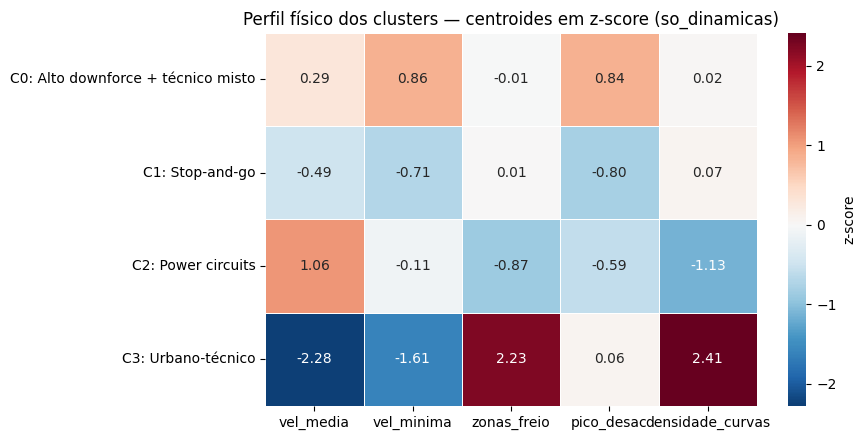

In [17]:
# Heatmap de centroides padronizados (z-score) — interpretação física dos clusters
centroides_z = pd.DataFrame(X, columns=FEATS)
centroides_z["cluster"] = final
centroides_z = centroides_z.groupby("cluster").mean()

# Renomear para legibilidade
centroides_z.index = [f"C{c}: {NOMES_CLUSTER[c]}" for c in centroides_z.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(centroides_z, cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            cbar_kws={"label": "z-score"}, linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Perfil físico dos clusters — centroides em z-score (so_dinamicas)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


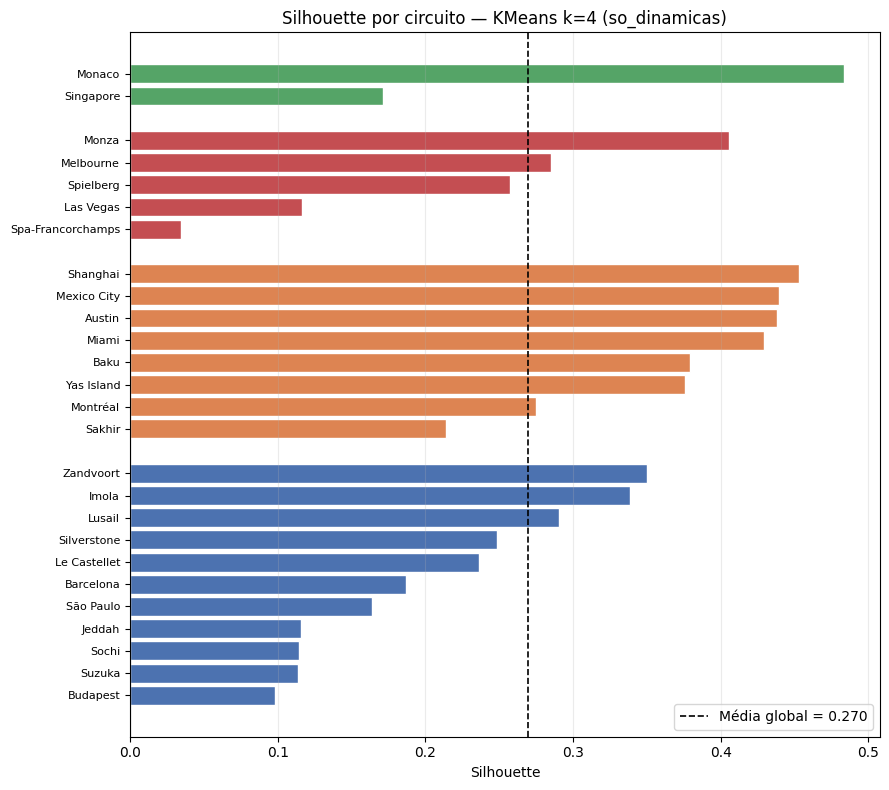


Circuitos com menor silhouette (boundary cases internos):
         circuito  cluster  silhouette
Spa-Francorchamps        2    0.034599
         Budapest        0    0.098066
           Suzuka        0    0.113631
            Sochi        0    0.114742
           Jeddah        0    0.115654


In [18]:
# Silhouette por circuito — diagnóstico de confiabilidade individual
from sklearn.metrics import silhouette_samples

sil_vals = silhouette_samples(X, final)
sil_df = pd.DataFrame({"circuito": df["circuito"].values,
                       "cluster": final, "silhouette": sil_vals})
sil_df = sil_df.sort_values(["cluster", "silhouette"], ascending=[True, True])

fig, ax = plt.subplots(figsize=(9, 8))
y_pos = 0
yticks, ylabels = [], []
for c in sorted(sil_df["cluster"].unique()):
    bloco = sil_df[sil_df["cluster"] == c]
    cor = CORES_CLUSTER[c]
    for _, row in bloco.iterrows():
        ax.barh(y_pos, row["silhouette"], color=cor, edgecolor="white", height=0.85)
        yticks.append(y_pos); ylabels.append(row["circuito"])
        y_pos += 1
    y_pos += 1  # gap entre clusters

ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=8)
ax.axvline(silhouette_score(X, final), color="black", linestyle="--",
           linewidth=1.2, label=f"Média global = {silhouette_score(X, final):.3f}")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Silhouette")
ax.set_title("Silhouette por circuito — KMeans k=4 (so_dinamicas)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print("\nCircuitos com menor silhouette (boundary cases internos):")
print(sil_df.sort_values("silhouette").head(5).to_string(index=False))


**Leitura conjunta das três visualizações.**

- **PCA** (79.4% da variância nas duas componentes): PC1 captura o eixo velocidade-fluidez — `vel_media` (+0.59) puxa para a direita, enquanto `densidade_curvas` (−0.51) e `zonas_freio` (−0.51) puxam para a esquerda. PC1+ é circuito rápido e aberto; PC1− é circuito lento e técnico. Os clusters 2 (power) e 3 (urbano-técnico) ocupam os extremos. PC2 é dominado por `pico_desac` (+0.75) e `vel_minima` (+0.56): PC2− concentra frenagens severas (pico_desac muito negativo) e mínimas baixas, o padrão característico do cluster 1 (stop-and-go).

- **Heatmap de centroides**: cada cluster tem assinatura física distinta. *Power* (C2): `vel_media` e `densidade_curvas` opostas em magnitude. *Urbano-técnico* (C3): `vel_media` e `vel_minima` muito negativas, `densidade_curvas` muito positiva. *Stop-and-go* (C1): `pico_desac` muito negativa (frenagens severas) com `vel_media` moderada. *Alto downforce + técnico misto* (C0): perfil intermediário, sem feature em destaque — o que é consistente com a fusão de dois núcleos persistentes documentada na §9.

- **Silhouette**: a média global de 0.270 reflete a natureza intermediária do problema. **Spa-Francorchamps destaca-se como o caso mais crítico** (silhouette = 0.034), confirmando o resultado da co-associação: é o único *boundary case puro* do dataset, sem afinidade estável com qualquer núcleo. Em seguida, com silhouette moderada-baixa (0.10–0.12), aparecem Budapest, Suzuka, Sochi e Jeddah, todos alocados ao Cluster 0 — esperado, dado que C0 é a fusão de dois núcleos persistentes (alto downforce + técnico misto) e portanto tem dispersão interna maior que os demais clusters.

## 11. Síntese da Etapa 1

**Decisão final.** A partição da Etapa 1 é `KMeans, so_dinamicas, k=4`, com silhouette = 0.270 e ARI médio em bootstrap = 0.818.

**Sequência de justificativas** (na ordem em que devem ser apresentadas para defensibilidade).

1. *Por que `k=4`*: a decisão tem **dupla ancoragem**.
   - **Estrutural**: restrição a priori — cardinalidade da feature-ponte para a Subgroup Discovery na Etapa 2.
   - **Estatística** (§7): k=4 é o único valor em que o KMeans converge para uma partição única em 200 seeds com `n_init=50` (determinismo perfeito, ARI=1.000). k=5 produz 7 estruturas distintas, com a modal em apenas 57% das seeds. A restrição da Etapa 2 coincide com o ponto de máxima estabilidade estatística do algoritmo.

2. *Por que `so_dinamicas`*: cada feature estática adicionada degrada silhouette monotonicamente (§§5–6). Com N=26, features estáticas são descritivas, não discriminantes.

3. *Por que KMeans sobre Ward*: Ward (silhouette 0.283) dilui os power circuits dentro de um cluster heterogêneo de 14 circuitos. KMeans (silhouette 0.270, diferença marginal de 0.013) isola Monza/Spielberg/Las Vegas/Spa/Melbourne em um cluster próprio, coerente com tipologia de literatura.

4. *Por que confiar no resultado*: além da estabilidade demonstrada em §7, a análise de co-associação (§9) confirma 5 núcleos empíricos persistentes alinhados com tipologia conhecida. 4 desses núcleos são preservados intactos na partição final; a única fusão (alto downforce + técnico misto no Cluster 0) é fisicamente coerente. Spa-Francorchamps é o único boundary case puro do dataset (max co-assoc = 0.60).

**Limitações documentadas.**

- `pico_desac` é a feature mais frágil: menor eta² de circuito (0.345), maior resíduo de era (~9%), concordância apenas moderada com Pirelli braking (ρ = −0.47).
- O Cluster 0 (n=11) tem dispersão interna maior que os demais por ser fusão de dois núcleos persistentes; reflete-se em silhouette baixa para circuitos como Budapest, Suzuka, Sochi e Jeddah.
- Spa-Francorchamps é boundary case empírico irredutível — sua alocação ao Cluster 2 (power) na partição final é a alocação modal, mas não estável.

**Ponte para a Etapa 2.** O `cluster_id` derivado desta partição entrará como feature categórica na base piloto × corrida da Subgroup Discovery, permitindo descobrir padrões estratégicos condicionais ao tipo de circuito sem expor o modelo a alta cardinalidade de circuitos individuais.